<a href="https://colab.research.google.com/github/mariagordiyenko86-maker/llm/blob/main/Assignment_1_PDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
#My seed - 3352607
#My githhub link - https://github.com/mariagordiyenko86-maker/nlp.git

**PART A - Load and annotate**

In [4]:
!pip install syndisco
import json                 # to save the conversations
import random               # to choose random participants
import re                   # to find the rating in the model's answer
import torch                # the library that runs the model
import syndisco             # the library of this lab
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive/Colab Notebooks"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (Runtime > Change runtime type > T4 GPU)")


Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks
GPU: Tesla T4


In [5]:
#Importing data
items = pd.read_csv("items.csv")
items_rated = pd.read_csv("items_rated.csv")

#Printing the data frames
pd.set_option('display.max_columns', None)
pd.set_option('display.expand_frame_repr', False)
print('\n', items)
print('\n', items_rated)



     id                                               text  rating  label  evidence
0    1  Glad_you_are_back._This_week_I_type_with_broke...     NaN    NaN       NaN
1    2  Yeah, thank goodness for Obama, and Bush I/Cli...     NaN    NaN       NaN
2    3  Wasteful spenders tend to be republicans. GW B...     NaN    NaN       NaN
3    4  At least he didn't flip off the cop or he'd be...     NaN    NaN       NaN
4    5  It's not what M-103 says...it's the mentality ...     NaN    NaN       NaN
5    6  Very true in many ways but it simply ignore th...     NaN    NaN       NaN
6    7  Side note: Regarding the comment about Trump "...     NaN    NaN       NaN
7    8  I am tired of cowards. Cory Gardener is "study...     NaN    NaN       NaN
8    9  This is good news. Any business starting up or...     NaN    NaN       NaN
9   10  hey idiot from ottawa the demand for oil is IN...     NaN    NaN       NaN
10  11  Same way Trump did. The ignorant, the gullible...     NaN    NaN       NaN
11

**PART B - Your annotations in the notebook**

This section presents a histogram, a boxplot, and descriptive statistics summarizing my ratings of the texts. An analysis of these results follows.

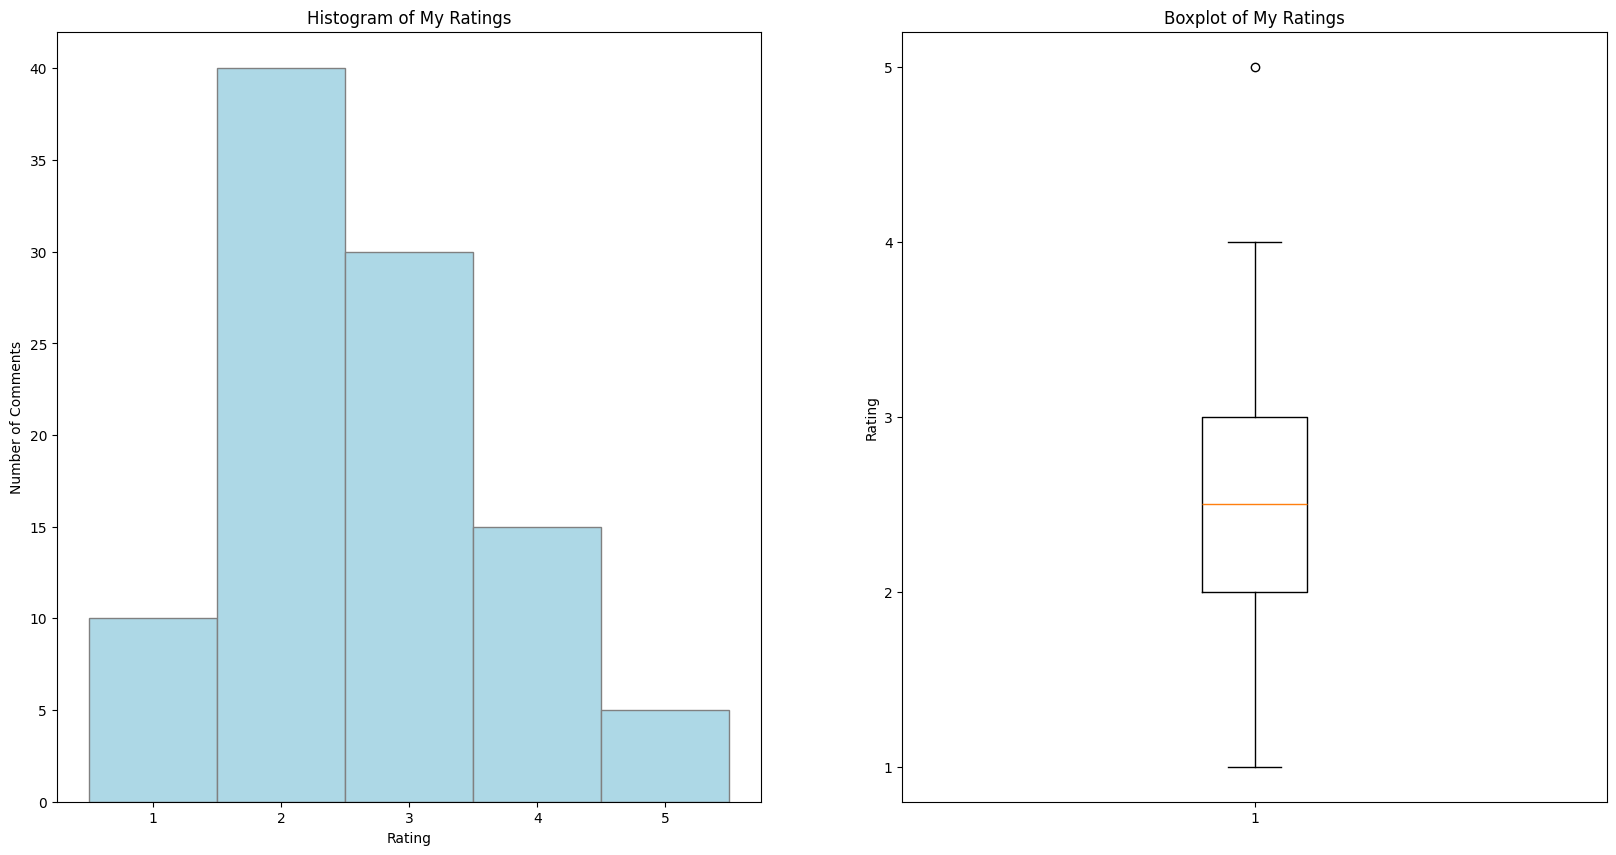

Statistics for My Ratings
count    20.00000
mean      2.65000
std       1.03999
min       1.00000
25%       2.00000
50%       2.50000
75%       3.00000
max       5.00000
Name: rating, dtype: float64


In [6]:
#Part B
#Plots to describe the items_rated : Histogram and Boxplot
fig = plt.figure(figsize = (20, 10))
hist_plot = fig.add_subplot(1, 2, 1)
box_plot = fig.add_subplot(1, 2, 2)

#Histogram
hist_plot.hist(items_rated['rating'], weights=[100 / len(items_rated)] * len(items_rated),\
               bins = [0.5, 1.5, 2.5, 3.5, 4.5, 5.5], color = 'lightblue', edgecolor = 'grey')
hist_plot.set_title('Histogram of My Ratings')
hist_plot.set_xlabel('Rating')
hist_plot.set_ylabel('Number of Comments')
hist_plot.set_xticks([1, 2, 3, 4, 5])

#Boxplot
box_plot.boxplot(items_rated['rating'])
box_plot.set_title('Boxplot of My Ratings')
box_plot.set_ylabel('Rating')
box_plot.set_yticks([1, 2, 3, 4, 5])
plt.show()

#Some statistics to validate the plots
stats = items_rated['rating'].describe()
print('Statistics for My Ratings')
print(stats)


**Comments**

From the histogram, we can observe that the most prevalent rating is 2 - Mostly civil, accounting for 40% of the ratings, followed by 3 - Borderline, which accounts for 30% of the ratings.

From the boxplot, we notice that 50% of the ratings (iqr) falls almost exactly between the ratings of 2 and 3. We can also observe one potential outlier, corresponding to a rating of 5.

According to the descriptive statistics, our distribution cannot be assumed to be normal as mean = 2.65 and median = 2.5. Our distribution is right-skewed  due to one outlier with rating 5.


**PART C - Generate one conversation per item**

Below, the LLM is instructed to generate one conversation per item.

Several changes were made to the code so that the conversations would have meaningful context:

1. **Personas.** Personas defined mainly by demographics do not necessarily have distinctive communication styles (for example, a nurse and a game developer could both be calm and empathetic). To produce realistic discussions with varied communication styles, two new attributes were added: `communication_style` and `conflict_response`.

   *Note:* In the first attempt, without these changes, the conversations were generic and similar to one another, lacking human traits such as empathetic or defensive communication.

2. **Context** The context was also revised to avoid generic, repetitive conversations. The LLM was instructed to respond to what the other participants actually say: to agree or disagree, to hold strong opinions, and even to criticise others. The goal was to produce conversations with meaningful, coherent context.

3. **Instructions** Instructions were also improved and are working mostly as guidelines. For example, the LLM should express an independent opinion without deliberately making the conversation more hostile or more civil. These guidelines were drafted with the help of an AI model, which was given the initial context along with the new rules. It was important to use AI model in order to construct useful and accurate guidelines, considering all the details that may introduce unwanted tone or making the conversation more hostile than originally intended.

4. **Model** The Qwen model was used in the first attempt. However, the conversations it produced lacked meaning, and its ratings were consistently 1–2 points higher than they should have been. For example, the text "Glad_you_are_back._This_week_I_type_with_broken_spacebar_and_broken_rib." was rated 3, even though it clearly belongs on the civil side of the scale. Carefully revising the instructions and context improved its performance. In the second attempt, the Llama model was used. It produced better conversations and more accurate ratings, at the cost of longer processing time. Since only 20 texts and 20 conversations are rated here, Llama was preferred for its better results.



In [7]:
#Loading the NLP model
model = syndisco.TransformersModel(
    model_path="unsloth/Llama-3.1-8B-Instruct-bnb-4bit",   # which model to download
    name="llama",                                         # a name for the logs
    max_out_tokens=80,                                   # longest answer: enough for a short reply
    generation_kwargs={"repetition_penalty": 1.1},       # avoids repeating the previous comment
)

config.json:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 5.70GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.5k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

In [8]:
# a small pool of made-up people: each is just a dictionary of attributes
PERSONAS = [
    {"username": "Maria", "age": 38, "job": "nurse", "personality": ["patient", "direct"],
     "communication_style": "calm, practical, empathetic", "conflict_response": "usually tries to de-escalate, but can become firm"},
    {"username": "Giannis", "age": 21, "job": "game developer", "personality": ["sarcastic", "curious"],
     "communication_style": "informal, witty, sometimes provocative", "conflict_response": "responds to provocation with sarcasm"},
    {"username": "Kimya", "age": 67, "job": "retired teacher", "personality": ["strict", "grumpy"],
     "communication_style": "assertive, opinionated, occasionally dismissive", "conflict_response": "can become impatient with comments she considers ignorant"},
    {"username": "Tom_77", "age": 45, "job": "truck driver", "personality": ["blunt", "funny"],
     "communication_style": "casual, straightforward, occasionally rough", "conflict_response": "confronts disagreement directly, sometimes with humor"},
    {"username": "Sofia", "age": 29, "job": "journalist", "personality": ["skeptical", "polite"],
     "communication_style": "measured, analytical, questioning", "conflict_response": "challenges claims without necessarily attacking people"},
]

# the same context and instructions for every participant
CONTEXT = (
    """You are participating in a realistic discussion thread on an online news website.

    The conversation takes place in response to a news article or public-interest
    topic. Participants have different opinions, communication styles, experiences,
    and levels of knowledge.

    The discussion should resemble naturally occurring online conversations,
    including:
    - Agreement and disagreement.
    - Strongly expressed opinions.
    - Criticism of arguments, decisions, and public figures.
    - Sarcasm, irony, humor, and frustration.
    - Misunderstandings and differences in interpretation.
    - Occasional personal defensiveness or impatience.
    - Constructive discussion and attempts to find common ground.

    Participants do not have to be polite or agree with each other at all times.
    However, the conversation should develop naturally rather than artificially
    escalating into hostility.

    People should respond to what others actually say, rather than introducing
    unrelated arguments or repeating generic opinions.

    The goal is to simulate realistic public discourse, not to make every
    participant either civil or toxic."""
)
INSTRUCTIONS = (
    """Write ONE natural reply to the latest comments in the discussion.

      Follow these rules:

      1. Write in the first person, as the assigned persona.
      2. Respond directly to something actually said in the previous comments.
      3. Maintain the persona's communication style and personality.
      4. Express an independent opinion. You may agree, disagree, partially agree,
        question, challenge, criticize, joke, or change your position.
      5. Vary your language, sentence structure, and conversational approach.
      6. Do not repeat arguments or expressions already used excessively in the thread.
      7. Do not introduce unrelated topics or invent factual information.
      8. Allow disagreement, frustration, sarcasm, bluntness, and occasional
        rudeness when they arise naturally from the conversation.
      9. Do not deliberately make every exchange more hostile. Conversations may
        escalate, remain civil, or become more constructive.
      10. Avoid making every reply sound polished, diplomatic, or carefully reasoned.
          Real commenters have different levels of articulateness and expressiveness.

      Write 1-3 sentences, preferably under 60 words."""
)

In [9]:
#Creating conversations
rng = random.Random(0)           # change the 0 to get other participants
conversations = {}               # will hold {text id: the conversation}

texts = dict(zip(items['id'], items['text']))
for i, t in texts.items():
    # 1. choose 3 of the 5 people and turn each one into an Actor (a model + persona + context + instructions)
    users = [
        syndisco.Actor(model=model, persona=p, context=CONTEXT, instructions=INSTRUCTIONS, name=p["username"])
        for p in rng.sample(PERSONAS, 3)
    ]
    # 2. set up the discussion
    discussion = syndisco.Discussion(
        next_turn_manager=syndisco.RandomTurnManager(users),  # who speaks next
        users=users,
        conv_len=4,                          # number of replies the model writes
        seed_opinions=[t],                   # the text itself opens the thread...
        seed_opinion_usernames=["OriginalPoster"],            # ...as if written by this user
    )
    # 3. run it and keep the log (the list of comments)
    discussion.begin(verbose=False)
    conversations[i] = discussion.get_logs()
print("done")

/usr/local/lib/python3.13/dist-packages/syndisco/turn_manager.py:163: UserWarning: 
                p_respond has been set to 0, which disables responding
                altogether. In that case, it may be better to use the
                RandomTurnManager class instead.
                
  warnings.warn(


  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and 

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

  0%|          | 0/4 [00:00<?, ?it/s]

... (32 outputs left out)

[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

  0%|          | 0/4 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

done


In [10]:
#Reading conversations
def as_text(logs):
    # one line per comment: "name: text"
    return "\n".join(f'{e["name"]}: {e["text"]}' for e in logs)

for i, logs in conversations.items():
    print(f"--- conversation {i} ---")
    print(as_text(logs), "\n")

--- conversation 1 ---
OriginalPoster: Glad_you_are_back._This_week_I_type_with_broken_spacebar_and_broken_rib.
Maria: "Sorry to hear that you're dealing with both physical and mechanical pain, OP! Hope the rib heals quickly and your spacebar gets fixed soon."
Sofia: "Thanks for the kind sentiment, Maria, but I'm more concerned about the state of our local healthcare system if someone can't get timely treatment for a broken rib. What's the holdup here?"
Tom_77: "Hey Sofia, don't get me wrong, I'm with you on this one. But let's not forget, my buddy broke his rib playing hockey over the weekend, and he got seen by a doc within hours. Maybe it's just bad luck or a weird scheduling thing?"
Maria: "I understand where you're coming from, Tom_77, but 'bad luck' isn't always the issue here. As a nurse, I've seen firsthand how long wait times can be due to systemic problems like understaffing and bureaucratic red tape. It's not just about individual cases; it's about the broader picture." 

--

In [11]:
#Saving conversations
with open("generated.jsonl", "w", encoding="utf-8") as f:
    for i, logs in conversations.items():
        entry = {"id": i, "conversation": [{"name": e["name"], "text": e["text"]} for e in logs]}
        f.write(json.dumps(entry, ensure_ascii=False) + "\n")
print("saved generated.jsonl")

saved generated.jsonl


**D and E - Annotate with and without context**

Below are the ratings produced by the AI annotators, both with and without context.

Before the AI annotators rated the texts, they were given clear rating instructions, and their personas were carefully defined.

1. **Rating instructions.** The AI annotators received the same rating instructions as the human annotator (myself), with a few adjustments.

2. **Annotator personas.** The AI annotators' personas were built from three attributes:

   - **Gender.** Men and women may perceive offensive or hostile language differently, so it will be interesting to examine whether their ratings disagree, and if so, by how much.
   - **Age.** Roughly half of the world's population is under 31, and the interquartile range spans approximately ages 18 to 48. Based on this, three age groups are used: 18–30, 31–40 and 41–50. The age group 41-50 was also created to include the opinion of older people . Younger annotators are expected to be more lenient than older ones. However, since all personas receive the same instructions, it is not certain that age will actually lead to different ratings.
   - **Education level.** Three levels are used: primary, secondary, and bachelor's degree or higher. The analysis will examine whether educational background affects how the texts are rated.

In [12]:
#Introducing personas
personas = {
    "woman": {"gender": "woman"},
    "man": {"gender": "man"},
    "18-30": {"age": "18-30"},
    "31-40": {"age": "31-40"},
    "41-50": {"age": "41-50"},
    "primary": {"education": "primary"},
    "secondary": {"education": "secondary"},
    "bachelor and above": {"education": "bachelor and above"},
}
ANNOTATORS = [None] + list(personas.values())    # baseline + the 8 personas

In [13]:
#Annotating with and without context
import re
import pandas as pd
from IPython.display import display

RATING_INSTRUCTIONS = (
    "How toxic is the comment? Answer with one number from 1 (fully civil) to 5 (very toxic).\n"
    "1	Fully civil. Respectful, even if the two sides disagree strongly.\n"
    "2	Mostly civil. Blunt, sarcastic or a little rude, but no attack on the person.\n"
    "3	Borderline. Clear disrespect: mocking, accusing the other of lying or bad faith, condescension.\n"
    "4	Toxic. Personal insults, name-calling, hostile or demeaning language aimed at a person or a group.\n"
    "5	Very toxic. Severe abuse: slurs, threats, harassment, hate.\n"
    "Rate the tone, not the topic. A controversial subject (abortion, politics, religion) is not toxic by itself, "
    "and a calm text defending an ugly view is judged on how it is said.\n"
    "A swear word is not automatically toxic: aimed at a person it counts, used for emphasis it counts much less.\n"
    "Quoted or reported words count less than words the writer says to someone.\n"
    "If the comment has several parts, let the most toxic part weigh most.\n"
    "Use your own judgement: careful readers disagree, and there is no wrong answer. Rate alone, and do not go back to change a rating.\n"
    "Give every item a rating. If you rate 3, 4 or 5, also give the words that make the text toxic, "
    "copied exactly from the comment: they are your evidence, and you need at least one.\n"
    "Answer in this format and add nothing else:\n"
    "for a 1 or a 2, only the number, e.g.: 2\n"
    "for a 3, 4 or 5, the number, a vertical bar and the words, e.g.: 4 | you idiot\n"
)
model.max_out_tokens = 40     # rating + a few quoted words; small, unlike part C

LABELS = {1: "civil", 2: "civil", 3: "toxic", 4: "toxic", 5: "toxic"}

def tokens(s):
    return re.findall(r"[\w']+", s.lower().replace("_", " "))

def parse(answer, text):
    """Rating, evidence and status. Invalid answers are marked, not fixed."""
    m = re.match(r"\s*([1-5])\s*(?:\|\s*(.*))?$", answer.strip(), re.S)
    if not m:
        return None, None, "no rating 1-5"
    rating, evidence = int(m.group(1)), (m.group(2) or "").strip() or None
    if rating <= 2:
        return rating, "not needed", "valid"
    if not evidence:
        return rating, None, "no words quoted"
    if any(w not in set(tokens(text)) for w in tokens(evidence)):
        return rating, evidence, "words not in item"
    return rating, evidence, "valid"

def rate(text, conversation=None, persona=None):
    # the context: the same sentence always; the conversation is added only in D
    context = "You are annotating comments from an online discussion."
    if conversation:
        context += " Before you rate, read the conversation that people had about the comment:\n" + conversation

    # the annotator: persona=None is the baseline; same instructions for everyone
    name = "baseline" if persona is None else ", ".join(persona.values())
    annotator = syndisco.Actor(
        model=model, persona=persona, context=context, instructions=RATING_INSTRUCTIONS,
        is_annotator=True, name=name,
    )

    # the log holds only the item, so only the item gets labelled
    logs = syndisco.Logs()
    logs.append("comment", text)

    job = syndisco.Annotation(annotator=annotator, discussion_logs=logs)
    job.begin(verbose=False)
    entry = job.get_logs()[0]
    answer = entry["text"]

    rating, evidence, status = parse(answer, text)
    return {
        "id": None, "text": text, "rating": rating, "label": LABELS.get(rating),
        "evidence": evidence, "annotator": name,
        "prompt": entry.get("prompt"),     # check this key in the test
        "raw answer": answer, "status": status,
    }

def run(items, annotators, with_conv):
    rows = []
    for persona in annotators:
        for i, t in items.items():
            row = rate(t, as_text(conversations[i]) if with_conv else None, persona)
            row["id"] = i
            rows.append(row)
    df = pd.DataFrame(rows)
    df["rating"] = df["rating"].astype("Int64")
    return df


In [14]:
test_items = dict(list(texts.items())[:3])
test = run(test_items, ANNOTATORS[:2], with_conv=True)
display(test)
print(test["prompt"].iloc[0])    # should show the prompt, not None

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


... (4 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


,id,text,rating,label,evidence,annotator,prompt,raw answer,status
0,1,Glad_you_are_back._This_week_I_type_with_broke...,1,civil,not needed,baseline,"{""context"": ""You are annotating comments from ...",1,valid
1,2,"Yeah, thank goodness for Obama, and Bush I/Cli...",3,toxic,"moronic, greedy",baseline,"{""context"": ""You are annotating comments from ...","3 | moronic, greedy",valid
2,3,Wasteful spenders tend to be republicans. GW B...,2,civil,not needed,baseline,"{""context"": ""You are annotating comments from ...",2,valid
3,1,Glad_you_are_back._This_week_I_type_with_broke...,1,civil,not needed,woman,"{""context"": ""You are annotating comments from ...",1,valid
4,2,"Yeah, thank goodness for Obama, and Bush I/Cli...",3,toxic,"moronic, greedy",woman,"{""context"": ""You are annotating comments from ...","3 | moronic, greedy",valid
5,3,Wasteful spenders tend to be republicans. GW B...,2,civil,not needed,woman,"{""context"": ""You are annotating comments from ...",2,valid


{"context": "You are annotating comments from an online discussion. Before you rate, read the conversation that people had about the comment:\nOriginalPoster: Glad_you_are_back._This_week_I_type_with_broken_spacebar_and_broken_rib.\nMaria: \"Sorry to hear that you're dealing with both physical and mechanical pain, OP! Hope the rib heals quickly and your spacebar gets fixed soon.\"\nSofia: \"Thanks for the kind sentiment, Maria, but I'm more concerned about the state of our local healthcare system if someone can't get timely treatment for a broken rib. What's the holdup here?\"\nTom_77: \"Hey Sofia, don't get me wrong, I'm with you on this one. But let's not forget, my buddy broke his rib playing hockey over the weekend, and he got seen by a doc within hours. Maybe it's just bad luck or a weird scheduling thing?\"\nMaria: \"I understand where you're coming from, Tom_77, but 'bad luck' isn't always the issue here. As a nurse, I've seen firsthand how long wait times can be due to systemic

In [15]:
%%capture run_log
table_D = run(texts, ANNOTATORS, with_conv=True).assign(context="D")    # with context
table_E = run(texts, ANNOTATORS, with_conv=False).assign(context="E")   # without context
results = pd.concat([table_D, table_E], ignore_index=True)
results.to_csv("annotations_D_E.csv", index=False)


[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://hug

In [16]:
COLUMNS = ["id", "text", "rating", "label", "evidence", "annotator", "prompt"]
short = lambda df: df.assign(text=df["text"].str[:60] + "...", prompt=df["prompt"].astype(str).str[:80] + "...")
print("D: with context");    display(short(table_D)[COLUMNS])
print("E: without context"); display(short(table_E)[COLUMNS])


D: with context


,id,text,rating,label,evidence,annotator,prompt
0,1,Glad_you_are_back._This_week_I_type_with_broke...,1,civil,not needed,baseline,"{""context"": ""You are annotating comments from ..."
1,2,"Yeah, thank goodness for Obama, and Bush I/Cli...",3,toxic,"moronic, greedy",baseline,"{""context"": ""You are annotating comments from ..."
2,3,Wasteful spenders tend to be republicans. GW B...,2,civil,not needed,baseline,"{""context"": ""You are annotating comments from ..."
3,4,At least he didn't flip off the cop or he'd be...,2,civil,not needed,baseline,"{""context"": ""You are annotating comments from ..."
4,5,It's not what M-103 says...it's the mentality ...,3,toxic,Shut up everybody,baseline,"{""context"": ""You are annotating comments from ..."
...,...,...,...,...,...,...,...
175,16,Thats population control for stupid and braind...,4,toxic,Thats population control for stupid and braind...,bachelor and above,"{""context"": ""You are annotating comments from ..."
176,17,Liberals like Dallaire and Junior are far beyo...,4,toxic,liberals like Dallaire and Junior are far beyo...,bachelor and above,"{""context"": ""You are annotating comments from ..."
177,18,"My motto? ""Support mental health or I'll kill ...",5,toxic,Support mental health or I'll kill you and you...,bachelor and above,"{""context"": ""You are annotating comments from ..."
178,19,"... stupid people are a fact of life, just loo...",3,toxic,"stupid people are a fact of life, just look at...",bachelor and above,"{""context"": ""You are annotating comments from ..."


E: without context


,id,text,rating,label,evidence,annotator,prompt
0,1,Glad_you_are_back._This_week_I_type_with_broke...,1,civil,not needed,baseline,"{""context"": ""You are annotating comments from ..."
1,2,"Yeah, thank goodness for Obama, and Bush I/Cli...",3,toxic,"moronic, greedy",baseline,"{""context"": ""You are annotating comments from ..."
2,3,Wasteful spenders tend to be republicans. GW B...,2,civil,not needed,baseline,"{""context"": ""You are annotating comments from ..."
3,4,At least he didn't flip off the cop or he'd be...,2,civil,not needed,baseline,"{""context"": ""You are annotating comments from ..."
4,5,It's not what M-103 says...it's the mentality ...,3,toxic,"religious terror, shut up",baseline,"{""context"": ""You are annotating comments from ..."
...,...,...,...,...,...,...,...
175,16,Thats population control for stupid and braind...,5,toxic,Thats population control for stupid and braind...,bachelor and above,"{""context"": ""You are annotating comments from ..."
176,17,Liberals like Dallaire and Junior are far beyo...,5,toxic,liberals like Dallaire and Junior are far beyo...,bachelor and above,"{""context"": ""You are annotating comments from ..."
177,18,"My motto? ""Support mental health or I'll kill ...",5,toxic,Support mental health or I'll kill you and you...,bachelor and above,"{""context"": ""You are annotating comments from ..."
178,19,"... stupid people are a fact of life, just loo...",3,toxic,"stupid people are a fact of life, just look at...",bachelor and above,"{""context"": ""You are annotating comments from ..."


In [17]:
# invalid answers per persona and condition, shown, not fixed
invalid = results[results["status"] != "valid"]
print(f"Invalid answers: {len(invalid)} of {len(results)}")
display(invalid.groupby(["annotator", "context", "status"]).size().unstack(fill_value=0))
display(invalid[["context", "annotator", "id", "raw answer", "status"]])

Invalid answers: 13 of 360


status                      words not in item
annotator          context                   
18-30              E                        1
31-40              E                        1
41-50              D                        1
                   E                        1
bachelor and above E                        1
baseline           E                        1
man                D                        1
                   E                        1
primary            D                        1
                   E                        1
secondary          E                        1
woman              D                        1
                   E                        1

,context,annotator,id,raw answer,status
35,D,woman,16,"4 | That's, braindead",words not in item
55,D,man,16,"4 | That's, braindead",words not in item
118,D,41-50,19,3 | stupid people \n\nThe comment starts off a...,words not in item
135,D,primary,16,"4 | That's, braindead",words not in item
187,E,baseline,8,"3 | coward, craven",words not in item
207,E,woman,8,"3 | coward, craven",words not in item
227,E,man,8,"3 | coward, craven",words not in item
247,E,18-30,8,"3 | coward, craven",words not in item
267,E,31-40,8,"3 | coward, craven",words not in item
287,E,41-50,8,"3 | coward, craven",words not in item


**Invalid answers.** 13 of the 360 answers (about 4%) were invalid, all because the evidence words were not found in the item. Most cases are minor mismatches rather than real errors: for item 8, all nine annotators in E quoted "coward" while the text says "cowards", and for item 16, "braindead" was quoted correctly but "That's" did not match the text. Only one answer, for item 19 in D, clearly broke the format by adding an explanation after the quoted words.

Since all 13 answers have invalid evidence due to small mismatches, these 13 answers were kept in all agreement calculations; no item was dropped.

In [18]:
#Overview: one column per annotator, next to my ratings
my_ratings = dict(zip(items_rated["id"], items_rated["rating"]))
ORDER = ["baseline"] + [", ".join(p.values()) for p in personas.values()]

def wide(df):
    w = df.pivot(index="id", columns="annotator", values="rating")[ORDER]
    w.insert(0, "you", w.index.map(my_ratings))
    w.insert(0, "text", w.index.map(lambda i: texts[i][:60] + "..."))
    w["invalid"] = df.groupby("id")["status"].apply(lambda s: (s != "valid").sum())
    return w.reset_index()

overview_D = wide(table_D)
overview_E = wide(table_E)

print("D: with context");    display(overview_D)
print("E: without context"); display(overview_E)

overview_D.to_csv("overview_D.csv", index=False)
overview_E.to_csv("overview_E.csv", index=False)

D: with context


annotator,id,text,you,baseline,woman,man,18-30,31-40,41-50,primary,secondary,bachelor and above,invalid
0,1,Glad_you_are_back._This_week_I_type_with_broke...,1,1,1,1,1,1,1,1,1,1,0
1,2,"Yeah, thank goodness for Obama, and Bush I/Cli...",2,3,3,3,3,3,3,3,3,3,0
2,3,Wasteful spenders tend to be republicans. GW B...,2,2,2,2,2,2,2,2,2,2,0
3,4,At least he didn't flip off the cop or he'd be...,2,2,2,2,2,2,2,2,2,2,0
4,5,It's not what M-103 says...it's the mentality ...,2,3,3,3,3,3,3,3,3,3,0
5,6,Very true in many ways but it simply ignore th...,2,2,2,2,2,2,2,2,2,2,0
6,7,"Side note: Regarding the comment about Trump ""...",4,2,2,2,2,2,2,2,2,2,0
7,8,"I am tired of cowards. Cory Gardener is ""study...",3,3,3,3,3,3,3,3,3,3,0
8,9,This is good news. Any business starting up or...,2,2,2,2,2,2,2,2,2,2,0
9,10,hey idiot from ottawa the demand for oil is IN...,4,4,4,4,4,4,4,4,4,4,0


E: without context


annotator,id,text,you,baseline,woman,man,18-30,31-40,41-50,primary,secondary,bachelor and above,invalid
0,1,Glad_you_are_back._This_week_I_type_with_broke...,1,1,1,1,1,1,1,1,1,1,0
1,2,"Yeah, thank goodness for Obama, and Bush I/Cli...",2,3,3,3,3,3,3,3,3,3,0
2,3,Wasteful spenders tend to be republicans. GW B...,2,2,2,2,2,2,2,2,2,3,0
3,4,At least he didn't flip off the cop or he'd be...,2,2,2,2,2,2,2,2,2,2,0
4,5,It's not what M-103 says...it's the mentality ...,2,3,3,3,3,3,5,3,3,5,0
5,6,Very true in many ways but it simply ignore th...,2,2,2,2,2,2,2,2,2,2,0
6,7,"Side note: Regarding the comment about Trump ""...",4,3,3,3,3,3,3,3,3,3,0
7,8,"I am tired of cowards. Cory Gardener is ""study...",3,3,3,3,3,3,3,3,3,3,9
8,9,This is good news. Any business starting up or...,2,2,2,2,2,2,2,2,2,2,0
9,10,hey idiot from ottawa the demand for oil is IN...,4,5,5,5,5,5,5,5,5,5,0


**F - Agreement**

**1. Me against each persona and the baseline, without context (E)**

Below is the code that measures how closely the annotators agree with my own ratings. It reports four main measures for each annotator:

- **agreement with me %**: the share of items on which the annotator gives the same civil/toxic label as me, as suggested in the hints of the exercise;
- **toxic share %**: how often the annotator labels an item as toxic, which shows the direction of the disagreement;
- **mean difference**: the average difference between the annotator's rating and mine on the 1–5 scale (positive: harsher than me; negative: more lenient);
- **RMSE**: the typical size of that difference, giving more weight to large disagreements.

The table also shows how many items were compared for each annotator, how many invalid answers were dropped, and whether an annotator gave the same label to every item.

After the code, three plots follow, each with a short comment:

1. a bar plot of how often each annotator agrees with me;
2. a bar plot of the direction of the disagreements, i.e. whether the annotators are harsher or more lenient than me;
3. boxplots of the ratings of each annotator and of my own, showing where the middle 50% of the ratings fall on the 1–5 scale.

In [19]:
#Me against each persona and the baseline, without context (E)

#Preparing the data
# my ratings and labels, indexed by id so everything is matched by item
mine = items_rated.set_index("id")[["rating"]].rename(columns={"rating": "me"})
mine["my label"] = mine["me"].map(LABELS)
# the model's ratings and labels in E, one column per annotator, indexed by id
ratings_E = table_E.pivot(index="id", columns="annotator", values="rating")[ORDER]
labels_E  = table_E.pivot(index="id", columns="annotator", values="label")[ORDER]
invalid_E = table_E.groupby("annotator")["status"].apply(lambda s: (s != "valid").sum())

rows = []
for a in ORDER: #once per annotator type
    # pandas aligns on id; items with an invalid answer are dropped
    both = pd.DataFrame({
        "me": mine["me"], "my label": mine["my label"],
        "model": ratings_E[a], "model label": labels_E[a],
    }).dropna()
    diff = both["model"].astype(int) - both["me"].astype(int)
    rows.append({
        "annotator": a,
        "n": len(both),
        "invalid (dropped)": invalid_E[a],
        "agreement with me %": (both["model label"] == both["my label"]).mean() * 100,
        "toxic share %": (both["model label"] == "toxic").mean() * 100,
        "mean diff (model - me)": diff.mean(),
        "RMSE": (diff ** 2).mean() ** 0.5,
    })

comparison_E = pd.DataFrame(rows).set_index("annotator")

# distance from the baseline, in items (one item = 5 points with 20 items)
base = comparison_E.loc["baseline", "agreement with me %"]
comparison_E["vs baseline (items)"] = (
    (comparison_E["agreement with me %"] - base) / (100 / comparison_E["n"])
).round(1)

display(comparison_E.round(2))

,n,invalid (dropped),agreement with me %,toxic share %,mean diff (model - me),RMSE,vs baseline (items)
annotator,,,,,,,
baseline,20,1,70.0,50.0,0.15,0.81,0.0
woman,20,1,75.0,45.0,0.15,0.81,1.0
man,20,1,75.0,45.0,0.15,0.81,1.0
18-30,20,1,75.0,45.0,0.15,0.81,1.0
31-40,20,1,75.0,45.0,0.15,0.81,1.0
41-50,20,1,75.0,45.0,0.25,1.02,1.0
primary,20,1,75.0,45.0,0.15,0.81,1.0
secondary,20,1,75.0,45.0,0.15,0.81,1.0
bachelor and above,20,1,65.0,55.0,0.35,1.07,-1.0


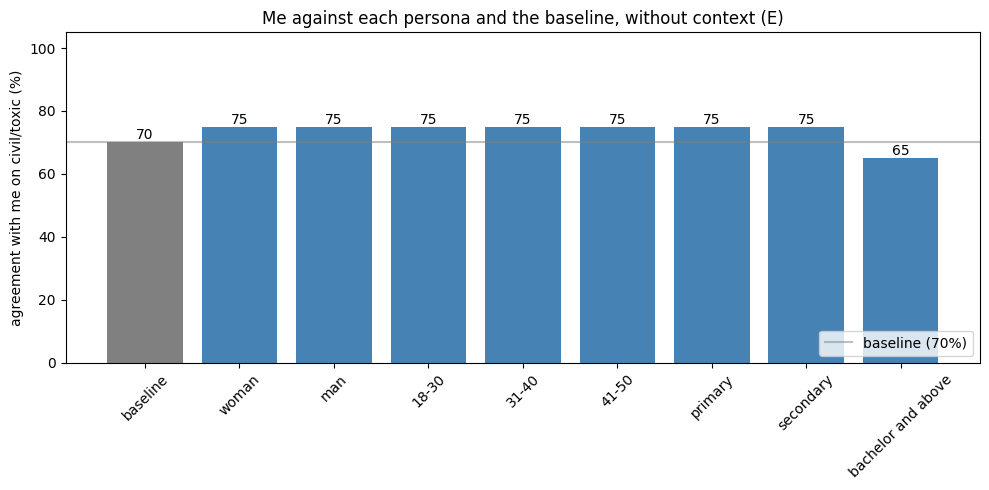

In [20]:
#Agreement with me, per annotator (E)

my_toxic = (mine["my label"] == "toxic").mean() * 100
constant_level = max(my_toxic, 100 - my_toxic)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["grey" if a == "baseline" else "steelblue" for a in comparison_E.index]
ax.bar(comparison_E.index, comparison_E["agreement with me %"], color=colors)

ax.axhline(base, color="grey", linestyle="-", alpha=0.5, label=f"baseline ({base:.0f}%)")

for i, v in enumerate(comparison_E["agreement with me %"]):
    ax.text(i, v + 1, f"{v:.0f}", ha="center")
ax.set_ylim(0, 105)
ax.set_ylabel("agreement with me on civil/toxic (%)")
ax.set_title("Me against each persona and the baseline, without context (E)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Comment 1.** The plot shows how often each annotator gives the same civil/toxic label as me. The grey bar is the baseline (no persona), the blue bars are the personas. Most personas agree with me on 75% of the items, so they disagree on 25% (5 of 20), which is not negligible. The baseline agrees on 70% (6 disagreements), and "bachelor and above" is the furthest from me, at 65% (7 disagreements). The plot does not show the direction of the disagreement, that is, whether the annotators label as toxic items that I found civil, or the other way round. This can be seen from the toxic share and the mean difference in the comparison table below.

,harsher,more lenient,total disagreements
annotator,,,
baseline,3,3,6
woman,2,3,5
man,2,3,5
18-30,2,3,5
31-40,2,3,5
41-50,2,3,5
primary,2,3,5
secondary,2,3,5
bachelor and above,4,3,7


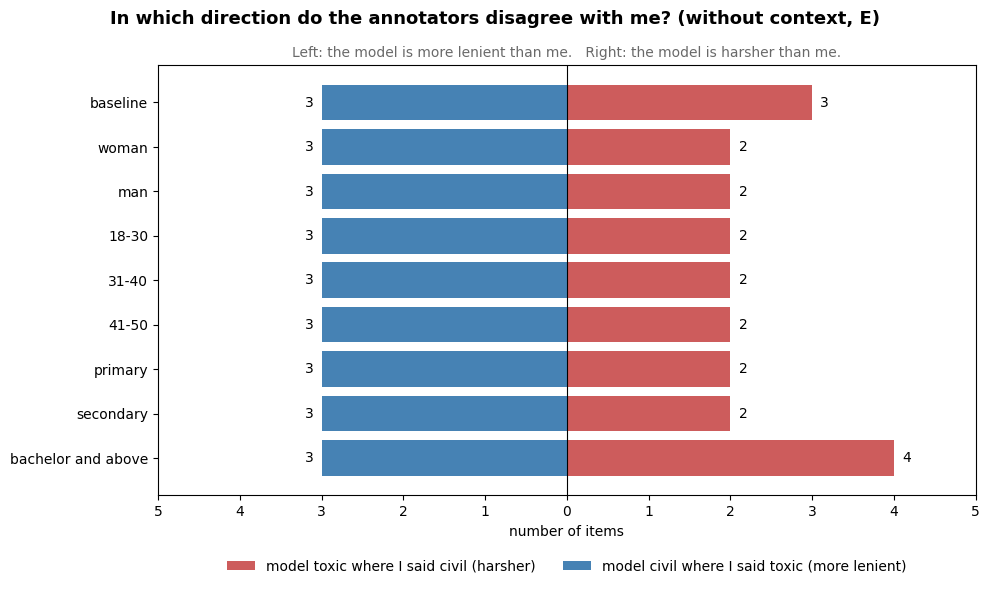

In [21]:
#In which direction do the annotators disagree with me? (E)

# count the two kinds of disagreement per annotator (items matched by id, invalid answers dropped)
direction = []
for a in ORDER:
    both = pd.DataFrame({"my label": mine["my label"], "model label": labels_E[a]}).dropna()
    direction.append({
        "annotator": a,
        "harsher": ((both["my label"] == "civil") & (both["model label"] == "toxic")).sum(),
        "more lenient": ((both["my label"] == "toxic") & (both["model label"] == "civil")).sum(),
    })
direction = pd.DataFrame(direction).set_index("annotator")
direction["total disagreements"] = direction["harsher"] + direction["more lenient"]
display(direction)

# diverging bar chart: harsher to the right, more lenient to the left
fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(direction))
ax.barh(y, direction["harsher"], color="indianred",
        label="model toxic where I said civil (harsher)")
ax.barh(y, -direction["more lenient"], color="steelblue",
        label="model civil where I said toxic (more lenient)")

# the counts next to the bars
for i, (h, l) in enumerate(zip(direction["harsher"], direction["more lenient"])):
    if h: ax.text(h + 0.1, i, str(h), va="center")
    if l: ax.text(-l - 0.1, i, str(l), va="center", ha="right")

# axes
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(list(y))
ax.set_yticklabels(direction.index)
ax.invert_yaxis()                                                    # baseline at the top
limit = int(direction[["harsher", "more lenient"]].values.max()) + 1
ax.set_xlim(-limit, limit)
ax.set_xticks(range(-limit, limit + 1))
ax.set_xticklabels([abs(t) for t in range(-limit, limit + 1)])       # counts, without minus signs
ax.set_xlabel("number of items")

# title and subtitle
fig.suptitle("In which direction do the annotators disagree with me? (without context, E)",
             fontsize=13, fontweight="bold")
ax.set_title("Left: the model is more lenient than me.   Right: the model is harsher than me.",
             fontsize=10, color="dimgray")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Comment 2** From the above chart, we may see the direction to which the annotators disagree with me. Whether it is to the civil or toxic side.
Specifically, the plot splits the disagreements with me into two parts: items the annotator labelled toxic while I labelled them civil (harsher, right), and items it labelled civil while I labelled them toxic (more lenient, left). The totals match the agreement plot: 6 disagreements for the baseline, 5 for most personas and 7 for "bachelor and above".

The disagreements go in both directions, so the model is neither systematically harsher nor more lenient than me. Every annotator is more lenient than me on exactly 3 items, which suggests these are the same three items for all of them: comments I found toxic but the model, whatever persona it plays, considers civil. On the harsher side, the annotators differ slightly: 2 items for most personas, 3 for the baseline and 4 for "bachelor and above".


/tmp/ipykernel_1665/300512444.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(data, labels=columns, patch_artist=True, widths=0.6,


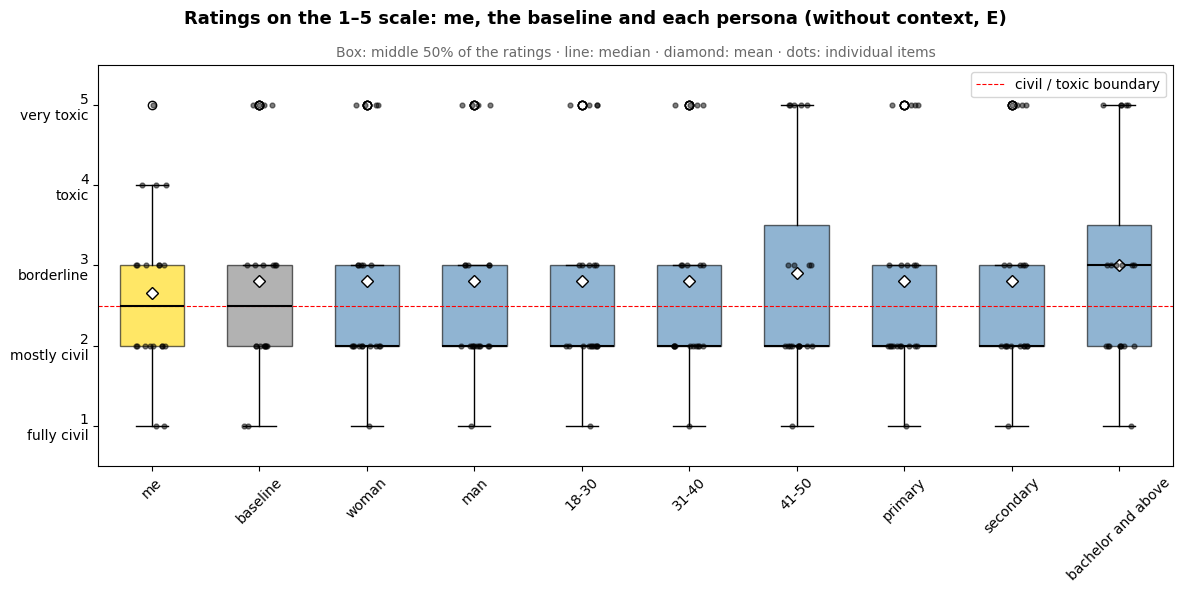

,me,baseline,woman,man,18-30,31-40,41-50,primary,secondary,bachelor and above
count,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.0
mean,2.65,2.80,2.80,2.80,2.80,2.80,2.90,2.80,2.80,3.0
std,1.04,1.28,1.24,1.24,1.24,1.24,1.33,1.24,1.24,1.3
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0
25%,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.0
50%,2.50,2.50,2.00,2.00,2.00,2.00,2.00,2.00,2.00,3.0
75%,3.00,3.00,3.00,3.00,3.00,3.00,3.50,3.00,3.00,3.5
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.0


In [22]:
#Ratings on the 1-5 scale: me, the baseline and each persona (E)

# one column per annotator, items matched by id; invalid answers dropped per annotator
columns = ["me"] + ORDER
data = [mine["me"].dropna().astype(int)] + [ratings_E[a].dropna().astype(int) for a in ORDER]

fig, ax = plt.subplots(figsize=(12, 6))
box = ax.boxplot(data, labels=columns, patch_artist=True, widths=0.6,
                 showmeans=True,
                 meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
                 medianprops=dict(color="black", linewidth=1.5))

# colours: me, baseline, personas
colors = ["gold", "grey"] + ["steelblue"] * len(personas)
for patch, c in zip(box["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)

# the individual ratings as dots, slightly spread out so they don't overlap
rng = np.random.default_rng(0)
for i, values in enumerate(data, start=1):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(values)), values, s=12, color="black", alpha=0.5, zorder=3)

ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(["1\nfully civil", "2\nmostly civil", "3\nborderline", "4\ntoxic", "5\nvery toxic"])
ax.set_ylim(0.5, 5.5)
ax.axhline(2.5, color="red", linestyle="--", linewidth=0.8, label="civil / toxic boundary")
ax.tick_params(axis="x", rotation=45)

fig.suptitle("Ratings on the 1–5 scale: me, the baseline and each persona (without context, E)",
             fontsize=13, fontweight="bold")
ax.set_title("Box: middle 50% of the ratings · line: median · diamond: mean · dots: individual items",
             fontsize=10, color="dimgray")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# the same in numbers
display(pd.DataFrame({c: d.describe() for c, d in zip(columns, data)}).round(2))

**Comment 3** The boxplots compare the distribution of the ratings on the 1–5 scale. Overall, the annotators use the scale in a similar way to me: for me, the baseline and most personas, the middle 50% of the ratings lies between 2 (mostly civil) and 3 (borderline), and the means are close, around 2.7 for me and 2.8–3.0 for the annotators. The model is therefore only slightly harsher than me on average.

The clearest difference is how the scale is used above 3. I rated several items as 4 (toxic), while the model almost never uses 4: its ratings jump from 3 straight to 5 (very toxic). The model seems to judge more in extremes: an item is either borderline or very toxic, while I also use the level in between. This also explains why the means of the annotators are slightly higher than mine, although their medians (2) are slightly lower than mine (2.5): their few toxic items get a 5 instead of a 4.

Seven of the nine annotators have practically identical distributions. Only "41-50" and "bachelor and above" differ, with a box reaching 3.5, and "bachelor and above" has a median of 3, which fits its slightly harsher behaviour in the previous plot. These differences, however, come from one or two items. Note also that the boxplots compare only the overall distributions, not the ratings item by item: similar boxes do not mean that the annotators rated the same items in the same way, which is why the agreement and direction plots above are needed.

**2.Me against each persona and the baseline, with context (D)**


Same as in the first question, only now the ratings are with context.
As previously, we have four main measures for each annotator:

- **agreement with me %**: the share of items on which the annotator gives the same civil/toxic label as me, as suggested in the hints of the exercise;
- **toxic share %**: how often the annotator labels an item as toxic, which shows the direction of the disagreement;
- **mean difference**: the average difference between the annotator's rating and mine on the 1–5 scale (positive: harsher than me; negative: more lenient);
- **RMSE**: the typical size of that difference, giving more weight to large disagreements.

The table also shows how many items were compared for each annotator, how many invalid answers were dropped, and whether an annotator gave the same label to every item.

After the code, three plots follow, each with a short comment:

1. a bar plot of how often each annotator agrees with me;
2. a bar plot of the direction of the disagreements, i.e. whether the annotators are harsher or more lenient than me;
3. boxplots of the ratings of each annotator and of my own, showing where the middle 50% of the ratings fall on the 1–5 scale.

In [23]:
#Me against each persona and the baseline, with context (D)

# the model's ratings and labels in D, one column per annotator, indexed by id
ratings_D = table_D.pivot(index="id", columns="annotator", values="rating")[ORDER]
labels_D  = table_D.pivot(index="id", columns="annotator", values="label")[ORDER]
invalid_D = table_D.groupby("annotator")["status"].apply(lambda s: (s != "valid").sum())

rows = []
for a in ORDER:
    # pandas aligns on id; items with an invalid answer are dropped
    both = pd.DataFrame({
        "me": mine["me"], "my label": mine["my label"],
        "model": ratings_D[a], "model label": labels_D[a],
    }).dropna()
    diff = both["model"].astype(int) - both["me"].astype(int)
    rows.append({
        "annotator": a,
        "n": len(both),
        "invalid (dropped)": invalid_D[a],
        "agreement with me %": (both["model label"] == both["my label"]).mean() * 100,
        "toxic share %": (both["model label"] == "toxic").mean() * 100,
        "mean diff (model - me)": diff.mean(),
        "RMSE": (diff ** 2).mean() ** 0.5,
    })

comparison_D = pd.DataFrame(rows).set_index("annotator")

# distance from the baseline, in items (one item = 5 points with 20 items)
base_D = comparison_D.loc["baseline", "agreement with me %"]
comparison_D["vs baseline (items)"] = (
    (comparison_D["agreement with me %"] - base_D) / (100 / comparison_D["n"])
).round(1)

display(comparison_D.round(2))

,n,invalid (dropped),agreement with me %,toxic share %,mean diff (model - me),RMSE,vs baseline (items)
annotator,,,,,,,
baseline,20,0,65.0,45.0,0.00,0.77,0.0
woman,20,1,65.0,45.0,0.00,0.77,0.0
man,20,1,65.0,45.0,0.00,0.77,0.0
18-30,20,0,70.0,50.0,0.05,0.74,1.0
31-40,20,0,70.0,50.0,0.05,0.74,1.0
41-50,20,1,70.0,50.0,0.05,0.74,1.0
primary,20,1,65.0,45.0,0.00,0.77,0.0
secondary,20,0,65.0,45.0,0.00,0.77,0.0
bachelor and above,20,0,70.0,50.0,0.05,0.74,1.0


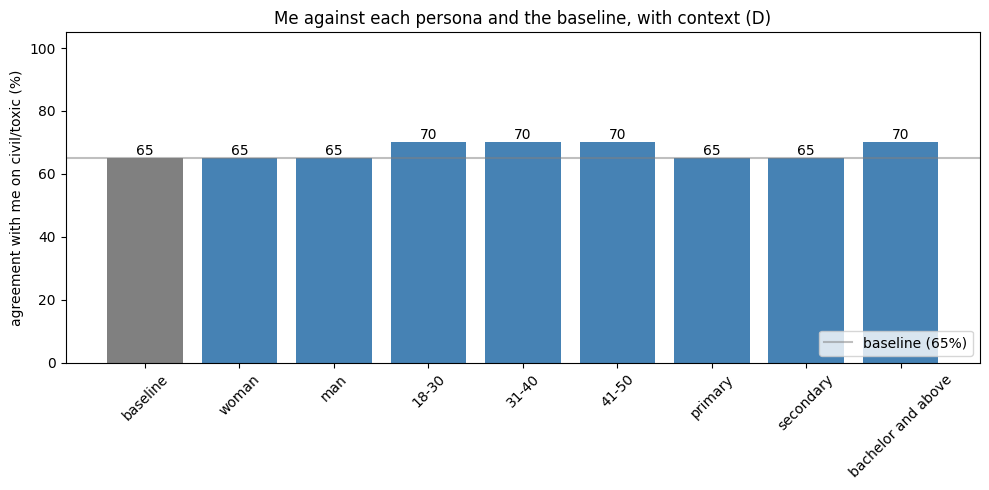

In [24]:
#Agreement with me, per annotator (D)

my_toxic = (mine["my label"] == "toxic").mean() * 100
constant_level = max(my_toxic, 100 - my_toxic)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["grey" if a == "baseline" else "steelblue" for a in comparison_D.index]
ax.bar(comparison_D.index, comparison_D["agreement with me %"], color=colors)

ax.axhline(base_D, color="grey", linestyle="-", alpha=0.5, label=f"baseline ({base_D:.0f}%)")

for i, v in enumerate(comparison_D["agreement with me %"]):
    ax.text(i, v + 1, f"{v:.0f}", ha="center")
ax.set_ylim(0, 105)
ax.set_ylabel("agreement with me on civil/toxic (%)")
ax.set_title("Me against each persona and the baseline, with context (D)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Comment 1**

**Does the context bring the annotators closer to me?** With context, the annotators agree with my civil/toxic labels on 65–70% of the items (13–14 of 20). This is still clearly above the 50% that coin flips, but it is lower than without context, where most annotators reached 75%. Reading the conversation therefore does not bring the models closer to me; if anything, it moves them slightly further away.

**Which identity annotates most like me?** Each persona has a single attribute, so the closest identity is described by that one attribute. Without context, seven personas share the first place (75%); with context, the three age groups and "bachelor and above" share it (70%). The only personas that are among the closest in both conditions are the three **age groups (18-30, 31-40 and 41-50)**: they agree with me on 75% of the items without context and 70% with context, and they are one item closer to me than the baseline in both conditions. "Bachelor and above" moves the most in the opposite direction: it goes from the furthest from me without context to among the closest with context. Woman, man, primary and secondary move the most away from me, losing two items each, and with context they are no closer to me than the baseline.

**Do the personas differ from the baseline, and which dimension matters most?** Only barely. All differences between personas, and between a persona and the baseline, are one or two items, which with 20 items (5 percentage points per item) is within the noise. If any dimension matters, it is age: the three age groups always behave identically and stay closest to me in both conditions, while the two genders are identical to each other and, with context, to the baseline.

,harsher,more lenient,total disagreements
annotator,,,
baseline,3,4,7
woman,3,4,7
man,3,4,7
18-30,3,3,6
31-40,3,3,6
41-50,3,3,6
primary,3,4,7
secondary,3,4,7
bachelor and above,3,3,6


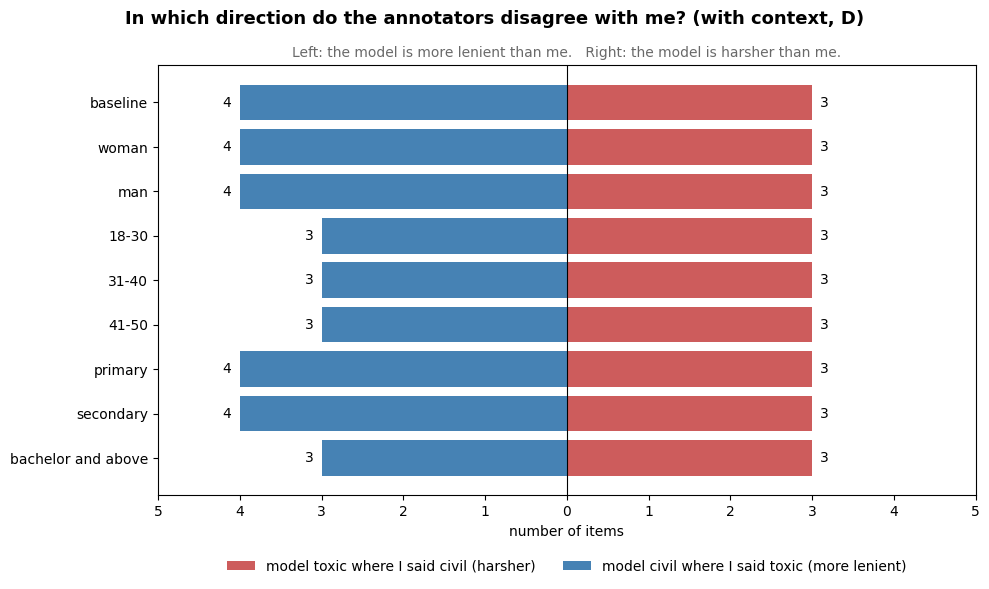

In [25]:
#In which direction do the annotators disagree with me? (D)

# count the two kinds of disagreement per annotator (items matched by id, invalid answers dropped)
direction_D = []
for a in ORDER:
    both = pd.DataFrame({"my label": mine["my label"], "model label": labels_D[a]}).dropna()
    direction_D.append({
        "annotator": a,
        "harsher": ((both["my label"] == "civil") & (both["model label"] == "toxic")).sum(),
        "more lenient": ((both["my label"] == "toxic") & (both["model label"] == "civil")).sum(),
    })
direction_D = pd.DataFrame(direction_D).set_index("annotator")
direction_D["total disagreements"] = direction_D["harsher"] + direction_D["more lenient"]
display(direction_D)

# diverging bar chart: harsher to the right, more lenient to the left
fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(direction_D))
ax.barh(y, direction_D["harsher"], color="indianred",
        label="model toxic where I said civil (harsher)")
ax.barh(y, -direction_D["more lenient"], color="steelblue",
        label="model civil where I said toxic (more lenient)")

# the counts next to the bars
for i, (h, l) in enumerate(zip(direction_D["harsher"], direction_D["more lenient"])):
    if h: ax.text(h + 0.1, i, str(h), va="center")
    if l: ax.text(-l - 0.1, i, str(l), va="center", ha="right")

# axes
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(list(y))
ax.set_yticklabels(direction_D.index)
ax.invert_yaxis()                                                    # baseline at the top
limit = int(direction_D[["harsher", "more lenient"]].values.max()) + 1
ax.set_xlim(-limit, limit)
ax.set_xticks(range(-limit, limit + 1))
ax.set_xticklabels([abs(t) for t in range(-limit, limit + 1)])       # counts, without minus signs
ax.set_xlabel("number of items")

# title and subtitle
fig.suptitle("In which direction do the annotators disagree with me? (with context, D)",
             fontsize=13, fontweight="bold")
ax.set_title("Left: the model is more lenient than me.   Right: the model is harsher than me.",
             fontsize=10, color="dimgray")

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

**Comment 2**

**In which direction does the context move the labels?** With context, the annotators disagree with me on 6–7 items, in both directions. All annotators are harsher than me on 3 items, labelling as toxic comments I found civil, and more lenient on 3 or 4 items. Compared with the condition without context, both sides grow by about one item: most personas were harsher on 2 items and more lenient on 3, and with context they are harsher on 3 and more lenient on 3–4. The context therefore does not push the model clearly in one direction; it adds roughly one disagreement on each side.

The identities that move the most are woman, man, primary and secondary: each gains one harsher and one more lenient disagreement, which is why their agreement with me drops by two items. The three age groups gain only one harsher disagreement. "Bachelor and above" is the only annotator that becomes less harsh with context (4 items in E, 3 in D), which explains why it is the only one that moves closer to me.

/tmp/ipykernel_1665/1704920622.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box = ax.boxplot(data_D, labels=columns, patch_artist=True, widths=0.6,


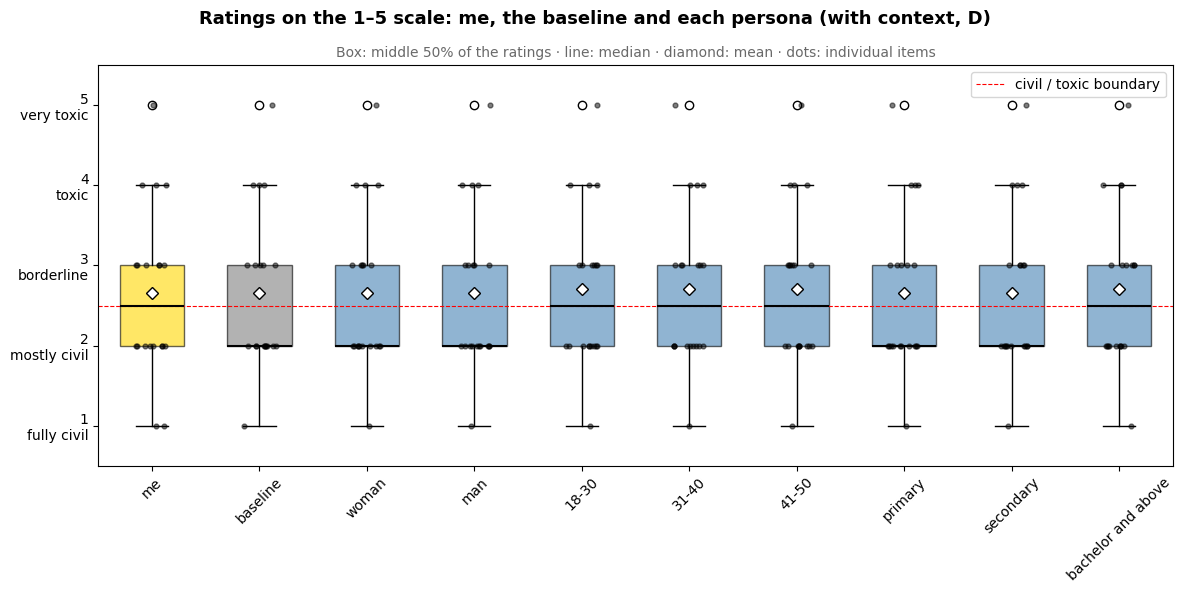

,me,baseline,woman,man,18-30,31-40,41-50,primary,secondary,bachelor and above
count,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.00,20.00
mean,2.65,2.65,2.65,2.65,2.70,2.70,2.70,2.65,2.65,2.70
std,1.04,0.99,0.99,0.99,0.98,0.98,0.98,0.99,0.99,0.98
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00
50%,2.50,2.00,2.00,2.00,2.50,2.50,2.50,2.00,2.00,2.50
75%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00


In [26]:
#Ratings on the 1-5 scale: me, the baseline and each persona (D)

# one column per annotator, items matched by id; invalid answers dropped per annotator
columns = ["me"] + ORDER
data_D = [mine["me"].dropna().astype(int)] + [ratings_D[a].dropna().astype(int) for a in ORDER]

fig, ax = plt.subplots(figsize=(12, 6))
box = ax.boxplot(data_D, labels=columns, patch_artist=True, widths=0.6,
                 showmeans=True,
                 meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor="black", markersize=6),
                 medianprops=dict(color="black", linewidth=1.5))

# colours: me, baseline, personas
colors = ["gold", "grey"] + ["steelblue"] * len(personas)
for patch, c in zip(box["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)

# the individual ratings as dots, slightly spread out so they don't overlap
rng = np.random.default_rng(0)
for i, values in enumerate(data_D, start=1):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(values)), values, s=12, color="black", alpha=0.5, zorder=3)

ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(["1\nfully civil", "2\nmostly civil", "3\nborderline", "4\ntoxic", "5\nvery toxic"])
ax.set_ylim(0.5, 5.5)
ax.axhline(2.5, color="red", linestyle="--", linewidth=0.8, label="civil / toxic boundary")
ax.tick_params(axis="x", rotation=45)

fig.suptitle("Ratings on the 1–5 scale: me, the baseline and each persona (with context, D)",
             fontsize=13, fontweight="bold")
ax.set_title("Box: middle 50% of the ratings · line: median · diamond: mean · dots: individual items",
             fontsize=10, color="dimgray")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

# the same in numbers
display(pd.DataFrame({c: d.describe() for c, d in zip(columns, data_D)}).round(2))

**Comment 3**

**How does the context change the use of the scale?** With context, the distributions of the annotators are almost identical to mine. All have the middle 50% of their ratings between 2 (mostly civil) and 3 (borderline), and their means (2.65–2.70) are practically equal to mine (2.65).

The most visible change compared with the condition without context is the use of the rating 4 (toxic). Without context, the model almost never gave a 4 and jumped from borderline straight to very toxic; with context, it uses 4 for several items, as I did. Reading the conversation therefore makes the model use the scale more like me, with less extreme ratings.

**Overall answer.** The context does not bring the models closer to me item by item: agreement drops by one or two items for most annotators. It does, however, make their ratings more balanced and their use of the scale more similar to mine. The identities closest to me, in both conditions, are the three age groups, one item closer than the baseline, but all differences between personas are within the noise of 20 items, so no identity annotates clearly more like me.

**3 - Each persona and the baseline, without against with context (E against D)**


Below, each annotator is compared with itself: its labels without context (E) against its labels with context (D). Agreement here shows how often the annotator keeps the same civil/toxic label when it reads the conversation. A high value means the context hardly changes its judgement; a low value means the context matters. For each annotator, the code reports:

- **agreement E–D %**: the share of items with the same label in both conditions;
- **toxic share in E and D %**: how often the annotator labels an item as toxic in each condition;
- **civil → toxic / toxic → civil**: how many labels changed, and in which direction;
- **mean change in rating (D − E)**: whether the context makes the annotator harsher (positive) or more lenient (negative) on the 1–5 scale.

Items with an invalid answer in either condition were dropped. After the code, two plots follow, each with a short comment: the agreement of each annotator with itself, and the direction of the changes.

In [27]:
#Each persona and the baseline: without against with context (E against D)

rows = []
for a in ORDER:
    # pandas aligns on id; items with an invalid answer in E or D are dropped
    both = pd.DataFrame({
        "E rating": ratings_E[a], "D rating": ratings_D[a],
        "E label": labels_E[a], "D label": labels_D[a],
    }).dropna()
    change = both["D rating"].astype(int) - both["E rating"].astype(int)
    rows.append({
        "annotator": a,
        "n": len(both),
        "invalid (dropped)": 20 - len(both),
        "agreement E–D %": (both["E label"] == both["D label"]).mean() * 100,
        "toxic share E %": (both["E label"] == "toxic").mean() * 100,
        "toxic share D %": (both["D label"] == "toxic").mean() * 100,
        "civil → toxic": ((both["E label"] == "civil") & (both["D label"] == "toxic")).sum(),
        "toxic → civil": ((both["E label"] == "toxic") & (both["D label"] == "civil")).sum(),
        "constant in E or D": both["E label"].nunique() == 1 or both["D label"].nunique() == 1,
        "mean change in rating (D - E)": change.mean(),
        "RMSE (D - E)": (change ** 2).mean() ** 0.5,
    })

e_vs_d = pd.DataFrame(rows).set_index("annotator")
display(e_vs_d.round(2))

,n,invalid (dropped),agreement E–D %,toxic share E %,toxic share D %,civil → toxic,toxic → civil,constant in E or D,mean change in rating (D - E),RMSE (D - E)
annotator,,,,,,,,,,
baseline,20,0,85.0,50.0,45.0,1,2,False,-0.15,0.59
woman,20,0,80.0,45.0,45.0,2,2,False,-0.15,0.59
man,20,0,80.0,45.0,45.0,2,2,False,-0.15,0.59
18-30,20,0,85.0,45.0,50.0,2,1,False,-0.10,0.55
31-40,20,0,85.0,45.0,50.0,2,1,False,-0.10,0.55
41-50,20,0,85.0,45.0,50.0,2,1,False,-0.20,0.71
primary,20,0,80.0,45.0,45.0,2,2,False,-0.15,0.59
secondary,20,0,80.0,45.0,45.0,2,2,False,-0.15,0.59
bachelor and above,20,0,85.0,55.0,50.0,1,2,False,-0.30,0.71


/tmp/ipykernel_1665/2367479722.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="lower right")


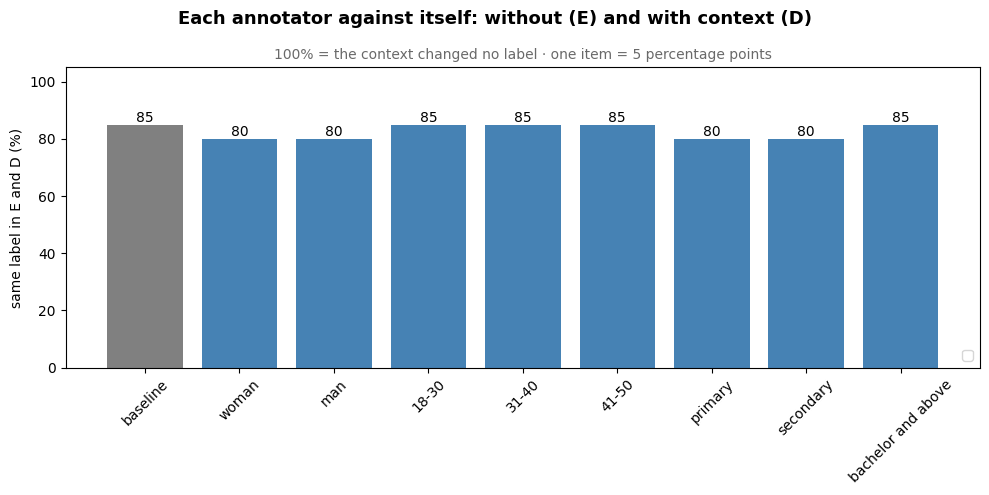

In [28]:
#How often does each annotator keep its label when it reads the conversation?

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["grey" if a == "baseline" else "steelblue" for a in e_vs_d.index]
bars = ax.bar(e_vs_d.index, e_vs_d["agreement E–D %"], color=colors)
ax.bar_label(bars, fmt="%.0f")
ax.set_ylim(0, 105)
ax.set_ylabel("same label in E and D (%)")
ax.tick_params(axis="x", rotation=45)
fig.suptitle("Each annotator against itself: without (E) and with context (D)",
             fontsize=13, fontweight="bold")
ax.set_title("100% = the context changed no label · one item = 5 percentage points",
             fontsize=10, color="dimgray")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Comment 1**

**How much does the context move an annotator on its own?** Here each annotator is compared with itself: how often it gives the same civil/toxic label to an item with and without context. All annotators keep most of their labels. The agreement between E and D is 80–85%, so reading the conversation changes the label of 3 or 4 items out of 20 (15–20%) for every annotator. The context therefore has a modest but real effect.

**Is the baseline moved more or less than the personas?** The baseline changes 3 labels (85%), the same as the three age groups and "bachelor and above". Woman, man, primary and secondary change one label more (4 items, 80%). The baseline is therefore moved about as much as the personas, and a difference of one item is within the noise of 20 items.

**Generally** Giving the model an identity does not make it more or less sensitive to the context. As in the earlier comparisons, the annotators fall into two groups with identical results, which again suggests that the persona hardly changes how the model reacts. In my view, the strict rating instructions may explain why the personas had so little effect. Because all annotators received the same detailed rules, there was little room left for the identity of each persona to influence its judgement. With more open guidelines, the differences between the personas might have been more visible.

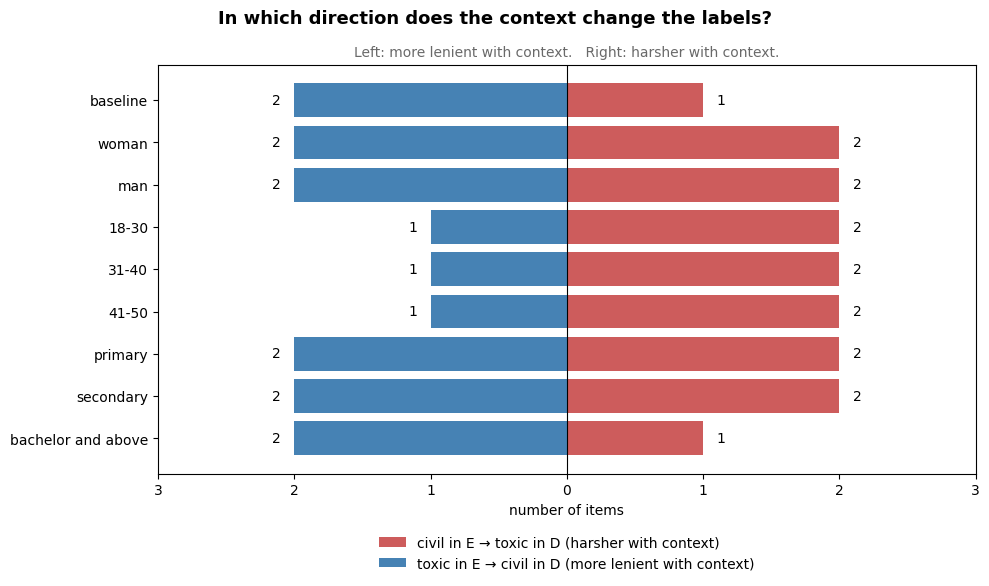

In [29]:
#In which direction does the context change the labels?
fig, ax = plt.subplots(figsize=(10, 6))
y = range(len(e_vs_d))
ax.barh(y, e_vs_d["civil → toxic"], color="indianred", label="civil in E → toxic in D (harsher with context)")
ax.barh(y, -e_vs_d["toxic → civil"], color="steelblue", label="toxic in E → civil in D (more lenient with context)")

for i, (h, l) in enumerate(zip(e_vs_d["civil → toxic"], e_vs_d["toxic → civil"])):
    if h: ax.text(h + 0.1, i, str(h), va="center")
    if l: ax.text(-l - 0.1, i, str(l), va="center", ha="right")

ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(list(y))
ax.set_yticklabels(e_vs_d.index)
ax.invert_yaxis()
limit = int(e_vs_d[["civil → toxic", "toxic → civil"]].values.max()) + 1
ax.set_xlim(-limit, limit)
ax.set_xticks(range(-limit, limit + 1))
ax.set_xticklabels([abs(t) for t in range(-limit, limit + 1)])
ax.set_xlabel("number of items")
fig.suptitle("In which direction does the context change the labels?", fontsize=13, fontweight="bold")
ax.set_title("Left: more lenient with context.   Right: harsher with context.", fontsize=10, color="dimgray")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, frameon=False)
plt.tight_layout()
plt.show()

**Comment 2**

**In which direction does the context change the labels?** The changes go in both directions. Woman, man, primary and secondary change two labels from civil to toxic and two from toxic to civil, so their changes balance out. The three age groups change two labels from civil to toxic and only one from toxic to civil, becoming slightly harsher with context, while the baseline and "bachelor and above" do the opposite (one harsher, two more lenient). The net effect is one item at most for every annotator, so the context does not make the model systematically harsher or more lenient: it changes how the model reads particular comments, not its overall strictness.

**Do these changes bring the annotators closer to me?** Combining these changes with the agreement with me (Question 2), most of them move the annotators away from me: woman, man, primary and secondary change 4 labels and lose 2 items of agreement with me (3 changes away from me, 1 towards me); the baseline and the age groups change 3 labels and lose 1 item (2 away, 1 towards). Only "bachelor and above" moves closer to me, gaining 1 item (2 changes towards me, 1 away). The context therefore moves the labels, but mostly not in the direction of my own judgement.

**4 - Persona against persona, within each condition (the baseline is one more annotator)**

Below, every annotator is compared with every other annotator, within each condition. The baseline is treated as one more annotator. For each pair, agreement is the share of items on which both give the same civil/toxic label; items where either annotator gave an invalid answer were dropped for that pair. The results are shown as two heatmaps, one for E (without context) and one for D (with context), together with the average agreement over all pairs in each condition.

High agreement between annotators means that the persona hardly changes the model's judgement: different "people" label the items the same way. Lower agreement for particular pairs shows which attributes (gender, age or education) actually lead to different labels.

In [30]:
#Persona against persona, within each condition (the baseline is one more annotator)

def pair_agreement(labels):
    """% of items on which two annotators give the same label (items matched by id, invalid dropped per pair)."""
    m = pd.DataFrame(index=ORDER, columns=ORDER, dtype=float)
    for a in ORDER:
        for b in ORDER:
            if a == b:
                m.loc[a, b] = 100.0          # an annotator always agrees with itself
                continue
            both = pd.DataFrame({"a": labels[a], "b": labels[b]}).dropna()
            m.loc[a, b] = (both["a"] == both["b"]).mean() * 100
    return m

def average_of_pairs(m):
    upper = np.triu_indices(len(m), k=1)      # each pair once, without the diagonal
    return m.values[upper].mean()

pairs = {"E (without context)": pair_agreement(labels_E),
         "D (with context)":    pair_agreement(labels_D)}

for cond, m in pairs.items():
    print(cond)
    display(m.round(0))

# average per condition, plus the lowest and highest pair
summary = []
for cond, m in pairs.items():
    upper = np.triu_indices(len(m), k=1)
    values = pd.Series(m.values[upper],
                       index=[f"{m.index[i]} – {m.columns[j]}" for i, j in zip(*upper)])
    summary.append({
        "condition": cond,
        "average agreement %": values.mean(),
        "lowest pair": f"{values.idxmin()} ({values.min():.0f}%)",
        "highest pair": f"{values.idxmax()} ({values.max():.0f}%)",
        "pairs at 100%": (values == 100).sum(),
        "number of pairs": len(values),
    })
display(pd.DataFrame(summary).set_index("condition").round(1))

E (without context)


,baseline,woman,man,18-30,31-40,41-50,primary,secondary,bachelor and above
baseline,100.0,95.0,95.0,95.0,95.0,95.0,95.0,95.0,95.0
woman,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
man,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
18-30,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
31-40,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
41-50,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
primary,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
secondary,95.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,90.0
bachelor and above,95.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,100.0


D (with context)


,baseline,woman,man,18-30,31-40,41-50,primary,secondary,bachelor and above
baseline,100.0,100.0,100.0,95.0,95.0,95.0,100.0,100.0,95.0
woman,100.0,100.0,100.0,95.0,95.0,95.0,100.0,100.0,95.0
man,100.0,100.0,100.0,95.0,95.0,95.0,100.0,100.0,95.0
18-30,95.0,95.0,95.0,100.0,100.0,100.0,95.0,95.0,100.0
31-40,95.0,95.0,95.0,100.0,100.0,100.0,95.0,95.0,100.0
41-50,95.0,95.0,95.0,100.0,100.0,100.0,95.0,95.0,100.0
primary,100.0,100.0,100.0,95.0,95.0,95.0,100.0,100.0,95.0
secondary,100.0,100.0,100.0,95.0,95.0,95.0,100.0,100.0,95.0
bachelor and above,95.0,95.0,95.0,100.0,100.0,100.0,95.0,95.0,100.0


,average agreement %,lowest pair,highest pair,pairs at 100%,number of pairs
condition,,,,,
E (without context),96.9,woman – bachelor and above (90%),woman – man (100%),21,36
D (with context),97.2,baseline – 18-30 (95%),baseline – woman (100%),16,36


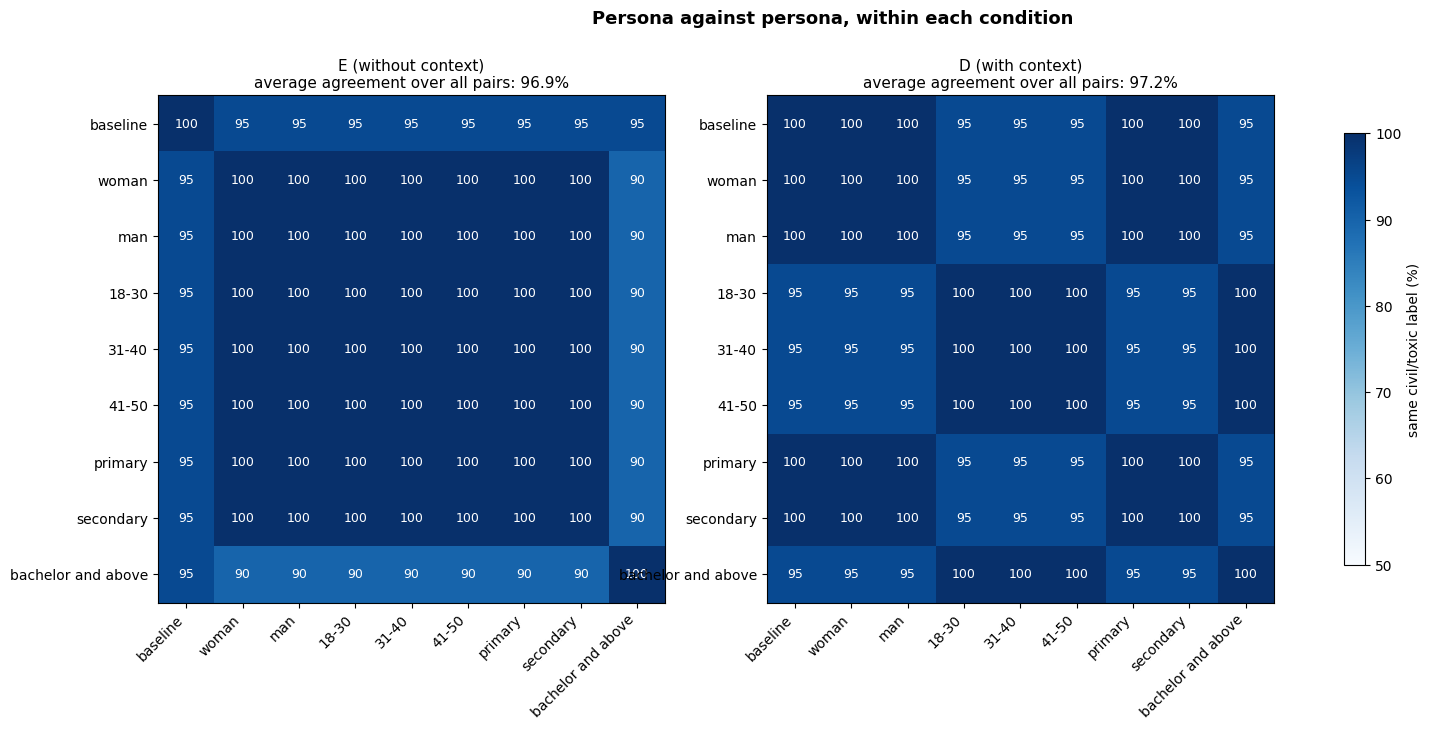

In [32]:
#Heatmaps: agreement of every pair, without (E) and with context (D)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, (cond, m) in zip(axes, pairs.items()):
    im = ax.imshow(m.values.astype(float), vmin=50, vmax=100, cmap="Blues")
    ax.set_xticks(range(len(m))); ax.set_xticklabels(m.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(m))); ax.set_yticklabels(m.index)
    for i in range(len(m)):
        for j in range(len(m)):
            v = m.iloc[i, j]
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    color="white" if v > 80 else "black", fontsize=9)
    ax.set_title(f"{cond}\naverage agreement over all pairs: {average_of_pairs(m):.1f}%", fontsize=11)

fig.colorbar(im, ax=axes, label="same civil/toxic label (%)", shrink=0.8)
fig.suptitle("Persona against persona, within each condition",
             fontsize=13, fontweight="bold")
plt.show()

**Comment**

**Does identity matter at all?** Hardly. The annotators agree with each other on 90–100% of the items in both conditions, far above the 50% that coin flips would give, and no pair disagrees on more than two items out of 20. The average agreement over all 36 pairs is 96.9% without context and 97.2% with context. Without context, seven of the eight personas (woman, man, the three age groups, primary and secondary) give exactly the same label to every item (21 of the 36 pairs agree on 100%).

**Which dimension separates the personas the most?** Education is the only dimension whose values ever disagree with each other. The two genders agree on 100% of the items in both conditions, and so do the three age groups. Only "bachelor and above" differs from "primary" and "secondary": by two items without context (90%) and by one item with context (95%).

**Key result**

**Which identity annotates most like me?**
Combining the closest value of each dimension, the identity that annotates most like me is **of any gender, any age, with primary or secondary education without context (75% agreement, 15 of 20 items), and with bachelor's education or above with context (70%, 14 of 20 items)**. Gender and age make no difference: woman and man, and all three age groups, give exactly the same labels. Education is the only dimension where the values differ, but by just one or two items.

Bellow you may find a hitmap with these attributes.



,E (without context),D (with context),change (items)
annotator,,,
baseline,70.0,65.0,-1.0
woman,75.0,65.0,-2.0
man,75.0,65.0,-2.0
18-30,75.0,70.0,-1.0
31-40,75.0,70.0,-1.0
41-50,75.0,70.0,-1.0
primary,75.0,65.0,-2.0
secondary,75.0,65.0,-2.0
bachelor and above,65.0,70.0,1.0


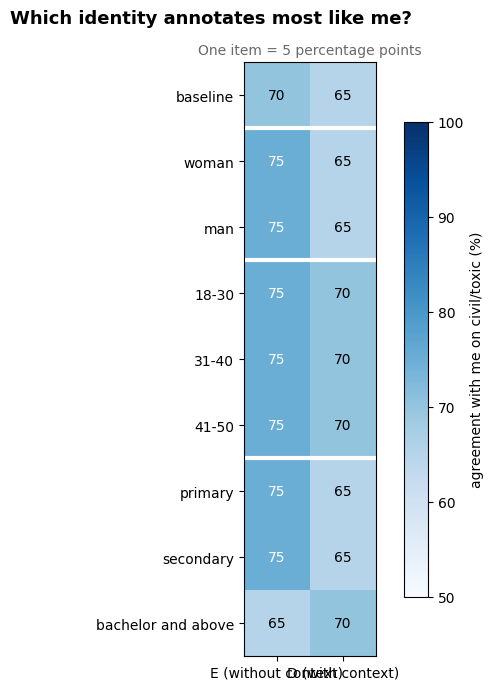

In [36]:
#Key result: agreement with me per attribute, without (E) and with context (D)
import matplotlib.pyplot as plt

dimensions = {"baseline": ["baseline"],
              "gender": ["woman", "man"],
              "age": ["18-30", "31-40", "41-50"],
              "education": ["primary", "secondary", "bachelor and above"]}
rows = [a for group in dimensions.values() for a in group]

grid = pd.DataFrame({
    "E (without context)": comparison_E.loc[rows, "agreement with me %"],
    "D (with context)":    comparison_D.loc[rows, "agreement with me %"],
})
grid["change (items)"] = (grid["D (with context)"] - grid["E (without context)"]) / 5
display(grid)

fig, ax = plt.subplots(figsize=(6, 7))
im = ax.imshow(grid[["E (without context)", "D (with context)"]].values, cmap="Blues", vmin=50, vmax=100)
ax.set_xticks([0, 1]); ax.set_xticklabels(["E (without context)", "D (with context)"])
ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
for i in range(len(rows)):
    for j in range(2):
        v = grid.iloc[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 70 else "black")

# lines between the dimensions
edge = 0
for group in list(dimensions.values())[:-1]:
    edge += len(group)
    ax.axhline(edge - 0.5, color="white", linewidth=3)

fig.colorbar(im, ax=ax, label="agreement with me on civil/toxic (%)", shrink=0.8)
fig.suptitle("Which identity annotates most like me?", fontsize=13, fontweight="bold")
ax.set_title("One item = 5 percentage points", fontsize=10, color="dimgray")
plt.tight_layout()
plt.show()